# ML Concepts as Screensavers
### Diffusion models, state-space models, and transformers — each rendered as a 15-minute loop

`math_of_ml_screensaver.ipynb` ended with particles tracing a learned stream
function on a tall 1:3 canvas. This notebook keeps that canvas and that trail
machinery, but each section takes one of the three architectures that dominate
modern ML, writes down its core equation, builds a working toy version, and
then turns the **mechanism itself** into the thing you watch:

- **Diffusion** — particles *are* samples. The screensaver is the reverse-time
  SDE running, over and over, toward five different target distributions.
- **State-space models** — the tall canvas *is* the sequence. The SSM scans it
  bottom-to-top and its ringing hidden state becomes a flow field.
- **Transformers** — particles *are* tokens. Every frame applies one attention
  layer to the whole cloud.

Each section renders a **15-minute, seamlessly looping MP4** at 480 × 1440
(1:3 portrait, 24 fps) for the same 30" × 10" vertical display as before.
Everything that drives a simulation is a periodic function of the loop length,
and the renderer crossfades the tail of the loop into its head so there is no
visible cut.

Needs a CUDA GPU, `torch`, and `ffmpeg` on PATH. A full 15-minute render takes
a few minutes per section on a GTX 1070. To iterate on the look, launch Jupyter
with `LOOP_SECONDS=30` in the environment and the same cells produce 30-second
loops instead.

In [1]:
import os, math, time, shutil, subprocess, tempfile
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import HTML, display

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'device: {device}' + (f'  ({torch.cuda.get_device_name(0)})' if device.type == 'cuda' else ''))
assert shutil.which('ffmpeg'), 'ffmpeg must be on PATH — frames are streamed straight into it'
torch.manual_seed(0); np.random.seed(0)

# Same dark theme as the screensaver notebook.
for k, v in {
    'figure.facecolor': '#0b0b14', 'axes.facecolor': '#0b0b14',
    'axes.edgecolor': '#444',     'axes.labelcolor': '#ddd',
    'xtick.color': '#888',         'ytick.color': '#888',
    'text.color': '#ddd',          'axes.titlecolor': '#eee',
}.items():
    plt.rcParams[k] = v

# Canvas geometry — 1:3 portrait, as before. Simulations live in a (±DOM_W, ±DOM_H) box.
DOM_W, DOM_H = 1.5, 4.5
CANVAS_W, CANVAS_H = 240, 720        # trail buffer
OUT_W, OUT_H = 480, 1440             # encoded video: 2× bilinear upscale of the buffer
FPS = 24
LOOP_SECONDS = int(os.environ.get('LOOP_SECONDS', 15 * 60))
print(f'loop length: {LOOP_SECONDS} s  →  {LOOP_SECONDS * FPS:,} frames per screensaver')

def phase(t, cycles=1):
    """Angle that completes `cycles` full turns per loop. Every driver uses this, so the loop closes."""
    return 2 * math.pi * cycles * t / LOOP_SECONDS

device: cuda  (NVIDIA GeForce GTX 1070)
loop length: 900 s  →  21,600 frames per screensaver


## Shared machinery — the trail canvas and the loop renderer

Two pieces carry over from the first notebook, slightly upgraded:

1. **The trail canvas.** An RGB intensity buffer on the GPU that fades a little
   every frame while particles splat their own color into it. Dense, glowing
   trails come from this accumulation — scatter markers can't do it. Particles
   outside the domain are simply not drawn (the old version pinned them to the
   edge).
2. **The loop renderer.** 15 minutes at 24 fps is 21,600 frames — far too many
   to embed as an inline animation, so frames go straight into `ffmpeg` as raw
   RGB. To make the loop seamless, the simulation runs a few seconds *past* the
   end and those frames are crossfaded into the first few seconds. A short
   pre-roll warms the trail buffer so frame 0 isn't black.

In [2]:
class Canvas:
    """RGB trail buffer on the GPU. Call decay() once per frame, then splat() any number of times."""
    def __init__(self, fade=0.95):
        self.buf = torch.zeros(3, CANVAS_H, CANVAS_W, device=device)
        self.fade = fade

    def decay(self):
        self.buf.mul_(self.fade)

    def splat(self, P, rgb, intensity):
        u = (P[:, 0] / (2 * DOM_W) + 0.5) * (CANVAS_W - 1)
        v = (P[:, 1] / (2 * DOM_H) + 0.5) * (CANVAS_H - 1)
        m = (u >= 0) & (u <= CANVAS_W - 1) & (v >= 0) & (v <= CANVAS_H - 1)
        idx = v[m].long() * CANVAS_W + u[m].long()
        w = intensity[m][:, None] if torch.is_tensor(intensity) else intensity
        self.buf.view(3, -1).index_add_(1, idx, (w * rgb[m]).T)

    def frame(self, gamma=0.7, scale=1.0):
        """uint8 (OUT_H, OUT_W, 3) image, top row first, ready for ffmpeg."""
        img = torch.clamp(self.buf * scale, 0, 1) ** gamma
        img = F.interpolate(img[None], size=(OUT_H, OUT_W), mode='bilinear', align_corners=False)[0]
        return (img.flip(1).permute(1, 2, 0) * 255).to(torch.uint8).cpu().numpy()


def _ffmpeg(path):
    cmd = ['ffmpeg', '-y', '-loglevel', 'error', '-f', 'rawvideo', '-pix_fmt', 'rgb24',
           '-s', f'{OUT_W}x{OUT_H}', '-r', str(FPS), '-i', '-',
           '-c:v', 'libx264', '-preset', 'fast', '-crf', '21', '-pix_fmt', 'yuv420p',
           '-movflags', '+faststart', path]
    return subprocess.Popen(cmd, stdin=subprocess.PIPE)


def render_loop(step, path, seconds=None, xfade=4.0, preroll=6.0, still_at=None):
    """Render step(t) -> uint8 frame for t in [0, seconds) into a seamlessly looping MP4.

    The simulation keeps running for `xfade` seconds past the end, and those frames are
    blended into the first `xfade` seconds, so the last frame flows into the first.
    `preroll` seconds are simulated but not recorded. Returns the frame nearest `still_at`
    seconds (or the last frame) so a poster image can be saved alongside the video.
    """
    seconds = seconds or LOOP_SECONDS
    n_total, n_x, n_pre = int(seconds * FPS), int(xfade * FPS), int(preroll * FPS)
    assert n_x < n_total, 'loop shorter than the crossfade'
    still_k = n_total - 1 if still_at is None else int(still_at * FPS)
    tmp = tempfile.mkdtemp()
    body_p, head_p = os.path.join(tmp, 'body.mp4'), os.path.join(tmp, 'head.mp4')
    t0 = time.time(); still = None

    for k in range(-n_pre, 0):                       # warm the trail buffer
        step(k / FPS)
    head = [step(k / FPS) for k in range(n_x)]       # held back until the tail exists
    if still_k < n_x: still = head[still_k]

    proc = _ffmpeg(body_p)
    for k in range(n_x, n_total):
        fr = step(k / FPS)
        if k == still_k: still = fr
        proc.stdin.write(fr.tobytes())
        if k % (60 * FPS) == 0:
            el = time.time() - t0
            print(f'  {k / FPS:5.0f} s of video | {el:5.0f} s elapsed | ~{el / (k + n_pre) * (n_total + n_x - k):4.0f} s left', flush=True)
    proc.stdin.close(); proc.wait()

    proc = _ffmpeg(head_p)
    for k in range(n_x):                             # tail → head crossfade
        a = k / n_x
        tail = step((n_total + k) / FPS).astype(np.float32)
        proc.stdin.write(((1 - a) * tail + a * head[k]).astype(np.uint8).tobytes())
    proc.stdin.close(); proc.wait()

    lst = os.path.join(tmp, 'list.txt')
    with open(lst, 'w') as f:
        f.write(f"file '{head_p}'\nfile '{body_p}'\n")
    subprocess.run(['ffmpeg', '-y', '-loglevel', 'error', '-f', 'concat', '-safe', '0',
                    '-i', lst, '-c', 'copy', path], check=True)
    shutil.rmtree(tmp)
    print(f'Saved → {path}  ({os.path.getsize(path) / 2**20:.0f} MB, {seconds / 60:.1f} min of video, '
          f'{time.time() - t0:.0f} s to render)')
    return still


def show_video(path, height=720):
    return HTML(f'<video src="{path}" height="{height}" loop autoplay muted controls '
                f'style="background:#000"></video>')

## 1. Diffusion models — learning to walk back from noise

A diffusion model never learns the data distribution $p(\mathbf{x})$ directly.
It learns something easier: the **score**, $\nabla_{\mathbf{x}} \log p_\sigma(\mathbf{x})$,
of a *blurred* version of the data, at every blur level $\sigma$.

**Forward process.** Take a data point and add Gaussian noise:
$\mathbf{x}_\sigma = \mathbf{x}_0 + \sigma\,\boldsymbol{\epsilon}$, with
$\boldsymbol{\epsilon} \sim \mathcal{N}(0, I)$. At $\sigma \to \infty$ every
dataset looks the same — a featureless Gaussian blob. That is the trick: the
blob is trivial to sample from.

**Learning the score.** For a single noised point the score of the Gaussian is
known exactly: $\nabla \log \mathcal{N}(\mathbf{x}_\sigma; \mathbf{x}_0, \sigma^2 I)
= -\boldsymbol{\epsilon}/\sigma$. Regressing a network onto that quantity
(*denoising score matching*) makes it converge to the score of the whole
blurred distribution, not just of one point:

$$\mathcal{L} = \mathbb{E}_{\mathbf{x}_0,\,\sigma,\,\boldsymbol{\epsilon}}
\big\|\, \sigma\, s_\theta(\mathbf{x}_0 + \sigma\boldsymbol{\epsilon},\, \sigma) + \boldsymbol{\epsilon} \,\big\|^2$$

So the network is really a **noise predictor**: "given this smudged point, which
way is the noise pointing?" Dividing by $\sigma$ turns that into a score.

**Reverse process.** Start from the blob and run time backwards. Removing a
slice of variance $\Delta\sigma^2 = \sigma_k^2 - \sigma_{k+1}^2$ is one
Euler–Maruyama step of the reverse-time SDE:

$$\mathbf{x}_{k+1} = \mathbf{x}_k + \Delta\sigma^2\, s_\theta(\mathbf{x}_k, \sigma_k)
+ \sqrt{\Delta\sigma^2}\,\mathbf{z}, \qquad \mathbf{z}\sim\mathcal{N}(0, I)$$

Drift along the score, re-inject a smaller dose of fresh noise, repeat with a
smaller $\sigma$. Image models do exactly this in a million dimensions; here we
do it in two, so every sample is a particle you can watch.

**Conditioning.** Feeding a class embedding into the network gives one model
that denoises toward whichever target you name — that's the "c" in
$s_\theta(\mathbf{x}, \sigma, c)$ and the mechanism behind text-conditioned
image generation.

step     0   DSM loss 1.0160


step  2000   DSM loss 0.6334


step  4000   DSM loss 0.6107


step  6000   DSM loss 0.6238


step  7999   DSM loss 0.6375
trained in 129.0 s


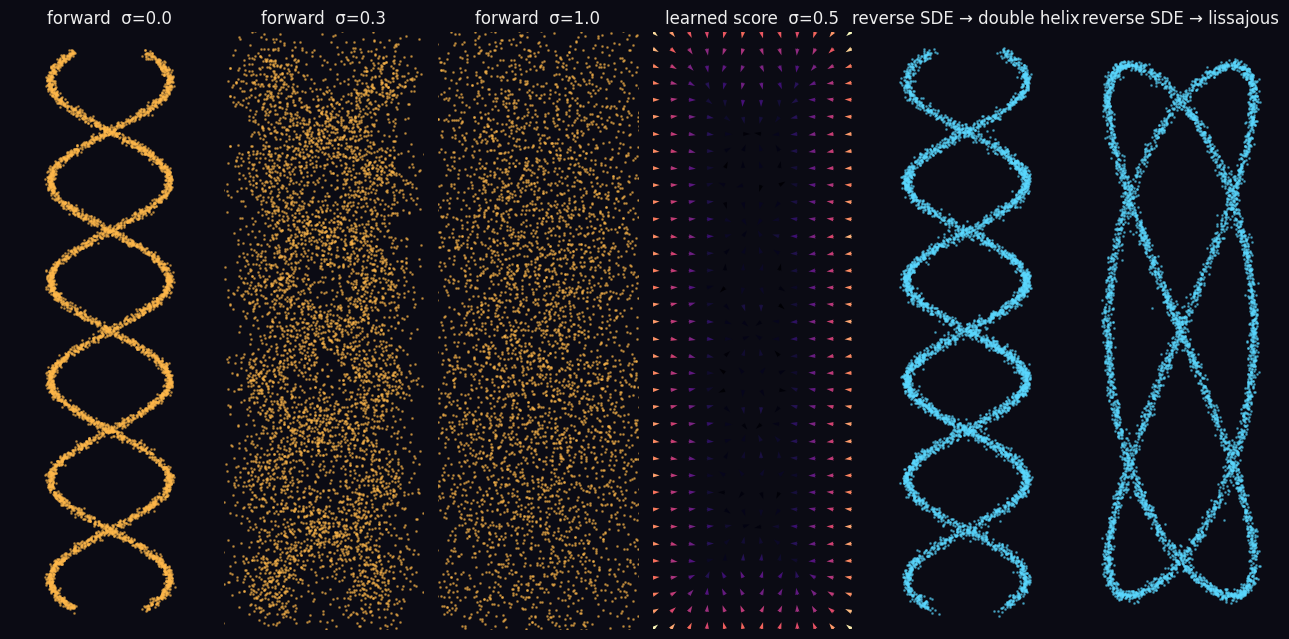

In [3]:
# ---- five 2-D "datasets" shaped for the tall canvas ----------------------
N_TARGETS = 5
TARGET_NAMES = ['double helix', 'three rings', 'lissajous', 'blob lattice', 'coil']

def make_target(kind, n, rng):
    if kind == 0:                                           # double helix
        y = rng.uniform(-4.2, 4.2, n); strand = rng.integers(0, 2, n) * np.pi
        x = 0.9 * np.sin(2 * np.pi * y / 3.0 + strand)
    elif kind == 1:                                         # three rings
        th = rng.uniform(0, 2 * np.pi, n); yc = rng.choice([-2.9, 0.0, 2.9], n)
        x, y = np.cos(th), yc + np.sin(th)
    elif kind == 2:                                         # lissajous 3:2
        s = rng.uniform(0, 2 * np.pi, n)
        x, y = 1.1 * np.sin(3 * s), 4.0 * np.sin(2 * s)
    elif kind == 3:                                         # lattice of blobs
        x = rng.integers(-1, 2, n) * 1.0 + rng.normal(0, 0.12, n)
        y = (rng.integers(0, 8, n) - 3.5) * 1.15 + rng.normal(0, 0.12, n)
    else:                                                   # coil, seen side-on
        u = rng.uniform(0, 1, n)
        x, y = np.cos(2 * np.pi * 7 * u), -4.2 + 8.4 * u + 0.3 * np.sin(2 * np.pi * 7 * u)
    return np.stack([x, y], 1) + rng.normal(0, 0.03, (n, 2))

rng  = np.random.default_rng(0)
data = torch.tensor(np.stack([make_target(k, 20000, rng) for k in range(N_TARGETS)]),
                    dtype=torch.float32, device=device)       # (5, 20000, 2)

# ---- noise schedule --------------------------------------------------------
SIG_MIN, SIG_MAX = 0.02, 2.5
def sigma_of(tau):
    """Geometric schedule. τ = 0 is pure noise (σ_max), τ = 1 is clean (σ_min)."""
    return SIG_MAX * (SIG_MIN / SIG_MAX) ** tau

# ---- the score network -----------------------------------------------------
class ScoreNet(nn.Module):
    """s_θ(x, σ, c) ≈ ∇_x log p_σ(x | c).
    Position and log σ both enter as multi-octave sin/cos features — a plain MLP on raw
    coordinates is spectrally biased and only ever learns the blurry envelope of the data.
    The class c is an embedding. The net predicts the noise ε; dividing by σ makes it a score."""
    def __init__(self, n_classes, hidden=192, octaves=6):
        super().__init__()
        self.emb = nn.Embedding(n_classes, 16)
        self.register_buffer('xfreq', math.pi * 2.0 ** torch.arange(octaves))        # over x/DOM
        self.register_buffer('sfreq', 0.5 * 2.0 ** torch.arange(6))                  # over log σ
        self.register_buffer('dom',   torch.tensor([DOM_W, DOM_H]))
        self.net = nn.Sequential(nn.Linear(2 + 4 * octaves + 12 + 16, hidden), nn.SiLU(),
                                 nn.Linear(hidden, hidden), nn.SiLU(),
                                 nn.Linear(hidden, hidden), nn.SiLU(),
                                 nn.Linear(hidden, 2))
    def forward(self, x, sigma, c):
        xn = x / self.dom
        xa = (xn[:, :, None] * self.xfreq).reshape(x.shape[0], -1)
        ls = torch.log(sigma)[:, None] * self.sfreq
        feats = torch.cat([xn, torch.sin(xa), torch.cos(xa), torch.sin(ls), torch.cos(ls), self.emb(c)], 1)
        return self.net(feats) / sigma[:, None]

score_net = ScoreNet(N_TARGETS).to(device)
opt   = torch.optim.Adam(score_net.parameters(), lr=2e-3)
STEPS = 8000
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, STEPS)
B = 4096; t0 = time.time()
for it in range(STEPS):
    c     = torch.randint(0, N_TARGETS, (B,), device=device)
    x0    = data[c, torch.randint(0, data.shape[1], (B,), device=device)]
    sigma = SIG_MIN * (SIG_MAX / SIG_MIN) ** torch.rand(B, device=device)     # log-uniform σ
    eps   = torch.randn_like(x0)
    loss  = ((sigma[:, None] * score_net(x0 + sigma[:, None] * eps, sigma, c) + eps) ** 2).mean()
    opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    if it % 2000 == 0 or it == STEPS - 1:
        print(f'step {it:5d}   DSM loss {loss.item():.4f}')
print(f'trained in {time.time() - t0:.1f} s')

# ---- sampling: Euler–Maruyama on the reverse-time SDE ----------------------
@torch.no_grad()
def reverse_step(x, c, tau, dtau, noise=1.0):
    g2  = sigma_of(tau) ** 2 - sigma_of(tau + dtau) ** 2        # variance removed this step
    sig = torch.full((x.shape[0],), sigma_of(tau), device=x.device)
    return x + g2 * score_net(x, sig, c) + noise * math.sqrt(g2) * torch.randn_like(x)

@torch.no_grad()
def sample(c, n, steps=400):
    x  = torch.randn(n, 2, device=device) * SIG_MAX
    cc = torch.full((n,), c, device=device, dtype=torch.long)
    for k in range(steps):
        x = reverse_step(x, cc, k / steps, 1 / steps)
    return x

# ---- does it work? forward process, learned score, reverse process --------
fig, axes = plt.subplots(1, 6, figsize=(13, 7))
x0 = data[0, :6000].cpu().numpy()
for ax, s in zip(axes[:3], [0.0, 0.3, 1.0]):
    pts = x0 + s * rng.normal(size=x0.shape)
    ax.scatter(pts[:, 0], pts[:, 1], s=1, c='#ffb84a', alpha=0.5)
    ax.set_title(f'forward  σ={s}')
gx, gy = np.meshgrid(np.linspace(-DOM_W, DOM_W, 12), np.linspace(-DOM_H, DOM_H, 36))
G  = torch.tensor(np.stack([gx.ravel(), gy.ravel()], 1), dtype=torch.float32, device=device)
with torch.no_grad():
    sc = score_net(G, torch.full((len(G),), 0.5, device=device),
                   torch.zeros(len(G), dtype=torch.long, device=device)).cpu().numpy()
mag = np.linalg.norm(sc, axis=1)
axes[3].quiver(gx.ravel(), gy.ravel(), sc[:, 0] / (mag + 1e-6), sc[:, 1] / (mag + 1e-6), mag,
               cmap='magma', scale=28, width=0.012)
axes[3].set_title('learned score  σ=0.5')
for ax, c in zip(axes[4:], [0, 2]):
    pts = sample(c, 6000).cpu().numpy()
    ax.scatter(pts[:, 0], pts[:, 1], s=1, c='#5ad8ff', alpha=0.5)
    ax.set_title(f'reverse SDE → {TARGET_NAMES[c]}')
for ax in axes:
    ax.set_xlim(-DOM_W, DOM_W); ax.set_ylim(-DOM_H, DOM_H); ax.set_aspect('equal'); ax.axis('off')
plt.tight_layout(); plt.show()

### The screensaver: ten denoisings

Particles start as pure noise and the reverse SDE pulls them, one step per
frame, onto the first target. They shimmer there for a moment under Langevin
dynamics at a small fixed $\sigma$, then the *forward* process dissolves them
back into noise and the next cycle begins with a different class label. Color
tracks the noise level — cold blue while the particle is noise, warming to the
target's hue as structure emerges — so you can literally watch the
signal-to-noise ratio rise.

Ten cycles of 90 seconds fill the 15 minutes, visiting each of the five targets
twice. The loop closes because a cycle both begins and ends in pure noise.

In [4]:
class DiffusionSaver:
    WARM = torch.tensor([[1.00, 0.80, 0.30], [1.00, 0.45, 0.35], [0.95, 0.35, 0.75],
                         [0.40, 1.00, 0.75], [0.55, 0.75, 1.00]], device=device)
    COLD = torch.tensor([0.20, 0.25, 0.90], device=device)
    DENOISE, HOLD = 0.55, 0.15          # fractions of a cycle; the remainder re-noises
    SIG_HOLD = 0.05                     # σ for the shimmer phase (and where denoising stops)

    def __init__(self, n=60000, seed=1):
        torch.manual_seed(seed)
        self.n = n
        self.x = torch.randn(n, 2, device=device) * SIG_MAX
        self.canvas = Canvas(fade=0.93)
        self.cycle = LOOP_SECONDS / (2 * N_TARGETS)
        self.tau_end = math.log(SIG_MAX / self.SIG_HOLD) / math.log(SIG_MAX / SIG_MIN)

    @torch.no_grad()
    def step(self, t):
        k  = math.floor(t / self.cycle)
        ph = t / self.cycle - k                                   # position inside the cycle
        c  = torch.full((self.n,), k % N_TARGETS, device=device, dtype=torch.long)
        nf = self.cycle * FPS
        if ph < self.DENOISE:                                     # reverse SDE: noise → data
            tau = ph / self.DENOISE * self.tau_end
            self.x = reverse_step(self.x, c, tau, self.tau_end / (self.DENOISE * nf))
            sigma = sigma_of(tau)
        elif ph < self.DENOISE + self.HOLD:                       # Langevin at fixed σ: shimmer
            sigma = self.SIG_HOLD; eps = 0.3 * sigma ** 2
            sig = torch.full((self.n,), sigma, device=device)
            self.x = self.x + eps * score_net(self.x, sig, c) + math.sqrt(2 * eps) * torch.randn_like(self.x)
        else:                                                     # forward SDE: data → noise
            frac = 1 - self.DENOISE - self.HOLD
            q0 = (ph - self.DENOISE - self.HOLD) / frac
            q1 = min(q0 + 1 / (frac * nf), 1.0)
            s0, s1 = sigma_of(self.tau_end * (1 - q0)), sigma_of(self.tau_end * (1 - q1))
            self.x = self.x + math.sqrt(max(s1 ** 2 - s0 ** 2, 0.0)) * torch.randn_like(self.x)
            sigma = s1
        self.x.clamp_(-3 * DOM_H, 3 * DOM_H)
        w = 1 - math.log(sigma / self.SIG_HOLD) / math.log(SIG_MAX / self.SIG_HOLD)   # 0 noise … 1 clean
        w = min(max(w, 0.0), 1.0)
        self.canvas.decay()
        # noise is spread thin (most of it is off-canvas at σ_max), so it gets a brighter splat
        self.canvas.splat(self.x, (1 - w) * self.COLD + w * self.WARM[c], 0.010 + 0.010 * w + 0.04 * (1 - w) ** 2)
        return self.canvas.frame(gamma=0.65)

saver = DiffusionSaver()
still = render_loop(saver.step, 'diffusion_loop.mp4', still_at=saver.cycle * saver.DENOISE)
plt.imsave('diffusion_still.png', still)
show_video('diffusion_loop.mp4')

Saved → diffusion_loop.mp4  (295 MB, 15.0 min of video, 364 s to render)


## 2. State-space models — a bank of damped oscillators with memory

A state-space model is the oldest idea in the notebook: a linear ODE driven by
an input,

$$\dot{\mathbf{h}}(t) = A\,\mathbf{h}(t) + B\,u(t), \qquad y(t) = C\,\mathbf{h}(t).$$

The hidden state $\mathbf{h}$ is the model's *memory* of everything $u$ has
done so far. S4, Mamba and friends make three moves on top of this:

**1. Discretize.** Sequences come in steps, so hold the input constant over
each step of length $\Delta$ (zero-order hold) and integrate the ODE exactly:

$$\bar{A} = e^{A\Delta}, \qquad \bar{B} = (\bar{A} - I)\,A^{-1} B, \qquad
\mathbf{h}_k = \bar{A}\,\mathbf{h}_{k-1} + \bar{B}\,u_k.$$

**2. Make $A$ diagonal and complex.** With $A = \mathrm{diag}(\lambda_n)$,
$\lambda_n = -\alpha_n + i\omega_n$, every state component is an independent
damped oscillator: $\alpha_n$ sets how fast it forgets, $\omega_n$ how fast it
rings. That is the whole of S4D. Because the recurrence is linear, it has a
twin: unrolling gives $y = K * u$ with the **kernel** $K_k = C\bar{A}^k\bar{B}$
— the model is both an RNN and a convolution, and you pick whichever is
cheaper.

**3. Make it selective.** Mamba lets $\Delta$ (and $B$, $C$) depend on the
input: $\Delta_k = f(u_k)$. A big step means "this input matters — overwrite the
state"; a tiny step means "ignore it, keep remembering." Input-dependence
breaks the convolution twin, but a diagonal linear recurrence can still be
computed in parallel with a cumulative sum — the *associative scan* — which is
why selective SSMs are fast on GPUs.

The cell below builds all three forms and checks they agree.

sequential vs parallel scan : max |Δ| = 1.11e-14
recurrence vs convolution   : max |Δ| = 2.29e-16


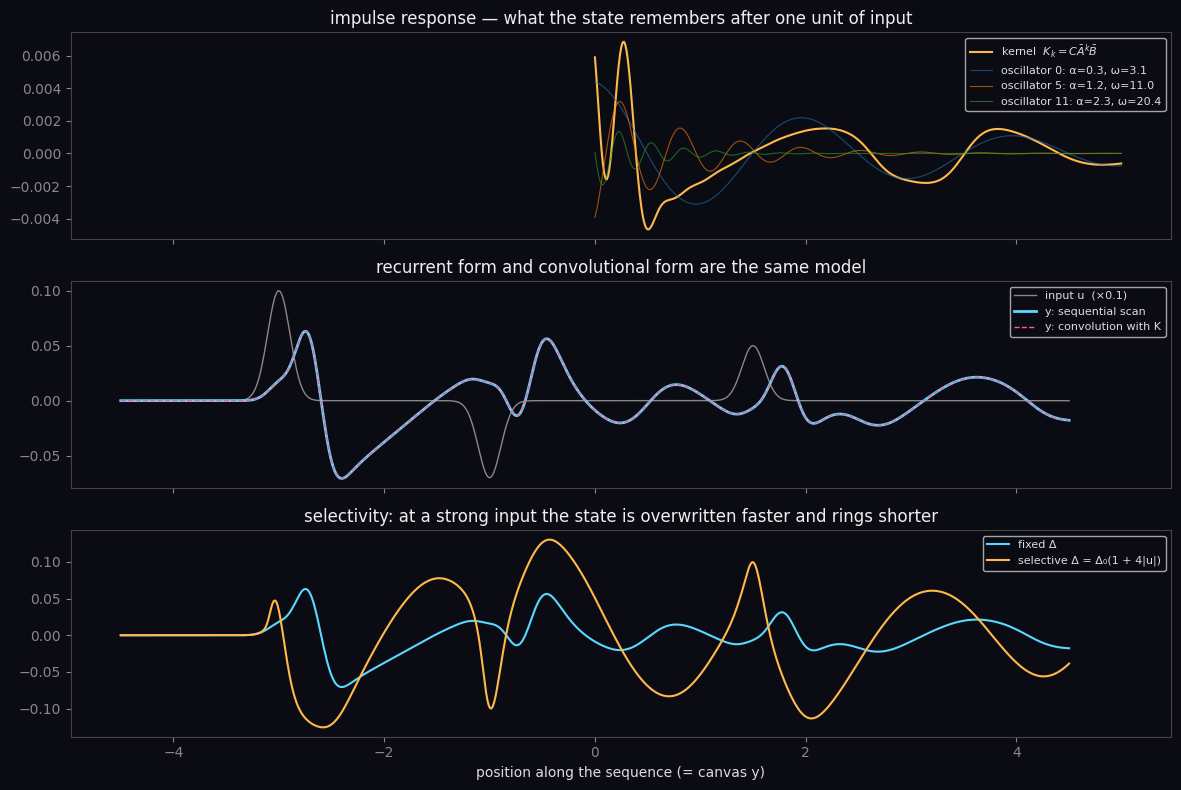

In [5]:
N_STATE = 12
L   = CANVAS_H                                   # sequence length = canvas rows (bottom → top)
ys  = np.linspace(-DOM_H, DOM_H, L)
dy  = ys[1] - ys[0]

# S4D-style initialisation: eigenvalues on a line in the left half-plane.
n     = np.arange(N_STATE)
alpha = 0.35 + 0.18 * n                          # memory length 1/α in y-units: 2.9 … 0.4
omega = np.pi * (1.0 + 0.5 * n)                  # ripple wavelength 2π/ω: 2.0 … 0.3
lam   = -alpha + 1j * omega                      # A = diag(λ)
B     = np.ones(N_STATE, dtype=complex)
C     = 0.35 * (0.6 + 0.4 * np.cos(1.3 * n)) * np.exp(1j * 0.7 * n)   # readout: one complex weight per oscillator

def discretize(delta):
    Abar = np.exp(lam * delta)
    return Abar, (Abar - 1) / lam * B

def scan_sequential(u, delta):
    """The RNN form, one step at a time. `delta` may be a scalar or per-step (selective)."""
    delta = np.broadcast_to(delta, (len(u),))
    h, hk = np.zeros((len(u), N_STATE), complex), np.zeros(N_STATE, complex)
    for k in range(len(u)):
        Abar, Bbar = discretize(delta[k])
        hk = Abar * hk + Bbar * u[k]
        h[k] = hk
    return h

def scan_parallel(u, delta):
    """Same recurrence with no Python loop. A is diagonal, so with S_k = Σ_{j≤k} λΔ_j:
         h_k = e^{S_k} · Σ_{j≤k} e^{-S_j} B̄_j u_j   — two cumulative sums. This is the associative scan."""
    delta = np.broadcast_to(delta, (len(u),))[:, None]
    S     = np.cumsum(lam[None, :] * delta, axis=0)
    Bbar  = (np.exp(lam[None, :] * delta) - 1) / lam[None, :] * B[None, :]
    return np.exp(S) * np.cumsum(np.exp(-S) * Bbar * u[:, None], axis=0)

def kernel(delta, length):
    """The convolution form: K_k = C Ā^k B̄."""
    Abar, Bbar = discretize(delta)
    return np.real((C * Bbar)[None, :] * Abar[None, :] ** np.arange(length)[:, None]).sum(1)

def readout(h):
    return np.real(h @ C)

# A test input: three bumps of different sign, like three plucks of a string.
u_test = sum(a * np.exp(-((ys - yc) / 0.15) ** 2) for a, yc in [(1.0, -3.0), (-0.7, -1.0), (0.5, 1.5)])
h_seq  = scan_sequential(u_test, dy)
h_par  = scan_parallel(u_test, dy)
y_conv = np.convolve(u_test, kernel(dy, L))[:L]
print(f'sequential vs parallel scan : max |Δ| = {np.abs(h_seq - h_par).max():.2e}')
print(f'recurrence vs convolution   : max |Δ| = {np.abs(readout(h_seq) - y_conv).max():.2e}')

delta_sel = dy * (1 + 4 * np.abs(u_test))        # selective: big inputs take big steps
h_sel = scan_parallel(u_test, delta_sel)

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
kk = kernel(dy, 400)
axes[0].plot(ys[:400] + DOM_H, kk, color='#ffb84a', lw=1.5, label='kernel  $K_k = C\\bar{A}^k\\bar{B}$')
for i in [0, 5, 11]:
    Abar, Bbar = discretize(dy)
    axes[0].plot(ys[:400] + DOM_H, np.real(C[i] * Bbar[i] * Abar[i] ** np.arange(400)), lw=0.8, alpha=0.6,
                 label=f'oscillator {i}: α={alpha[i]:.1f}, ω={omega[i]:.1f}')
axes[0].set_title('impulse response — what the state remembers after one unit of input'); axes[0].legend(fontsize=8)
axes[1].plot(ys, 0.1 * u_test, color='#888', lw=1, label='input u  (×0.1)')
axes[1].plot(ys, readout(h_seq), color='#5ad8ff', lw=2, label='y: sequential scan')
axes[1].plot(ys, y_conv, color='#ff5a8a', lw=1, ls='--', label='y: convolution with K')
axes[1].set_title('recurrent form and convolutional form are the same model'); axes[1].legend(fontsize=8)
axes[2].plot(ys, readout(h_par), color='#5ad8ff', lw=1.5, label='fixed Δ')
axes[2].plot(ys, readout(h_sel), color='#ffb84a', lw=1.5, label='selective Δ = Δ₀(1 + 4|u|)')
axes[2].set_title('selectivity: at a strong input the state is overwritten faster and rings shorter')
axes[2].legend(fontsize=8); axes[2].set_xlabel('position along the sequence (= canvas y)')
plt.tight_layout(); plt.show()

### The screensaver: the canvas is the sequence

The display is tall, so treat its vertical axis as time: every row is one
step, and the SSM scans from the bottom of the screen to the top. The input
$u(y, t)$ is a handful of Gaussian bumps whose positions drift slowly over the
15 minutes. Above each bump the hidden state rings like a struck bell — that
ringing *is* the impulse response from the plot above, drawn in space.

To make it visible, the readout $C$ turns the state at each row into a
**stream function** across the row: $\psi(x, y) = \mathrm{Re}\sum_n C_n h_n(y)\,e^{i\kappa_n x}$.
As in the first notebook, particles follow the perpendicular gradient
$(\partial_y\psi, -\partial_x\psi)$, which is divergence-free, so each ringing
oscillator becomes a street of counter-rotating vortices that fades out as the
state forgets. $\partial_y\psi$ needs $\mathrm{d}\mathbf{h}/\mathrm{d}y$ — which
is just the ODE's right-hand side, so the flow field is the model's own
dynamics. The readout phases rotate slowly so the vortex streets drift
sideways, and selective $\Delta$ is on, so the ringing compresses where inputs
are strong. Particles drift gently upward through the sequence and respawn in
the lower half. Color is the sign of $\psi$: teal cells turn one way, magenta
the other, violet where the state is quiet.

In [6]:
class SSMSaver:
    TEAL    = torch.tensor([0.30, 0.95, 0.90], device=device)
    VIOLET  = torch.tensor([0.35, 0.20, 0.90], device=device)
    MAGENTA = torch.tensor([1.00, 0.35, 0.70], device=device)

    def __init__(self, n=60000, seed=2, selective=True, swirl=2.2, drift=0.15, dt=0.03):
        torch.manual_seed(seed)
        self.n, self.selective, self.swirl, self.drift, self.dt = n, selective, swirl, drift, dt
        self.P = torch.stack([(torch.rand(n, device=device) * 2 - 1) * DOM_W,
                              (torch.rand(n, device=device) * 2 - 1) * DOM_H], 1)
        self.age = torch.rand(n, device=device) * 500
        self.canvas = Canvas(fade=0.95)
        # spatial wavenumbers for the readout: wavelengths 3, 1.5, 1 across the canvas width
        self.kappa = torch.tensor(np.pi / DOM_W * (1 + np.arange(N_STATE) % 3), dtype=torch.float32, device=device)

    def input(self, t):
        """u(y, t): six bumps whose centres sweep the height a few times per loop, over a faint
        slow wave so the state is never completely silent."""
        u = 0.2 * np.sin(1.3 * ys + phase(t, 2))
        for k in range(6):
            yc  = 3.8 * math.sin(phase(t, 2 + k) + 1.7 * k)
            amp = (-1) ** k * (0.7 + 0.3 * math.cos(phase(t, 1 + k) + 0.9 * k))
            u  += amp * np.exp(-((ys - yc) / 0.2) ** 2)
        return u

    @torch.no_grad()
    def step(self, t):
        u = self.input(t)
        delta = dy * (1 + 4 * np.abs(u)) if self.selective else dy
        h  = scan_parallel(u, delta) * (C * np.exp(1j * phase(t, 1 + n % 3)))[None, :]   # state × rotating readout
        H  = torch.tensor(h,                         dtype=torch.complex64, device=device)
        dH = torch.tensor(np.gradient(h, dy, axis=0), dtype=torch.complex64, device=device)

        r  = (self.P[:, 1] / (2 * DOM_H) + 0.5) * (L - 1)          # interpolate the state to each particle's row
        r0 = r.floor().clamp(0, L - 2).long(); f = (r - r0.float()).clamp(0, 1)[:, None]
        Hp, dHp = H[r0] * (1 - f) + H[r0 + 1] * f, dH[r0] * (1 - f) + dH[r0 + 1] * f
        e   = torch.exp(1j * self.kappa[None, :] * self.P[:, :1])   # e^{iκx}
        psi = (Hp * e).real.sum(1)
        ux  =  (dHp * e).real.sum(1)                                 # ∂ψ/∂y
        uy  = -(1j * self.kappa * Hp * e).real.sum(1)                # −∂ψ/∂x
        flow = torch.stack([ux, uy], 1) * self.swirl
        flow[:, 1] += self.drift
        flow = flow / torch.clamp(flow.norm(dim=1, keepdim=True) / 2.5, min=1.0)

        self.P = self.P + flow * self.dt
        self.age += 1
        out = (self.P[:, 1] > DOM_H) | (self.P[:, 0].abs() > DOM_W) | (self.age > 500)
        m = int(out.sum())
        if m:                                                        # respawn low, drift carries them up
            self.P[out, 0] = (torch.rand(m, device=device) * 2 - 1) * DOM_W
            self.P[out, 1] = (torch.rand(m, device=device) * 1.2 - 1.0) * DOM_H
            self.age[out] = 0
        w = torch.tanh(psi * 8)[:, None]                             # −1 … 1: which way the cell turns
        rgb = (1 - w.abs()) * self.VIOLET + w.clamp(min=0) * self.TEAL + (-w).clamp(min=0) * self.MAGENTA
        self.canvas.decay()
        self.canvas.splat(self.P, rgb, 0.014 + 0.008 * torch.clamp(flow.norm(dim=1), max=3.0))
        return self.canvas.frame(gamma=0.7)

saver = SSMSaver()
still = render_loop(saver.step, 'ssm_loop.mp4', still_at=LOOP_SECONDS * 0.3)
plt.imsave('ssm_still.png', still)
show_video('ssm_loop.mp4')

     60 s of video |   136 s elapsed | ~1745 s left


    120 s of video |   210 s elapsed | ~1304 s left


    180 s of video |   279 s elapsed | ~1087 s left


    240 s of video |   370 s elapsed | ~ 998 s left


    300 s of video |   466 s elapsed | ~ 920 s left


...

    660 s of video |  1125 s elapsed | ~ 412 s left


    720 s of video |  1212 s elapsed | ~ 307 s left


    780 s of video |  1353 s elapsed | ~ 213 s left


    840 s of video |  1464 s elapsed | ~ 111 s left


Saved → ssm_loop.mp4  (250 MB, 15.0 min of video, 1566 s to render)


## 3. Transformers — tokens that look at each other

A transformer layer is a rule for how a set of vectors updates itself by
*looking at the rest of the set*. Each token $i$ with feature vector
$\mathbf{f}_i$ produces three projections — a query, a key and a value:

$$\mathbf{q}_i = W_q\mathbf{f}_i, \qquad \mathbf{k}_j = W_k\mathbf{f}_j, \qquad \mathbf{v}_j = W_v\mathbf{f}_j.$$

The query is "what am I looking for", the key is "what I advertise", and the
dot product $\mathbf{q}_i\cdot\mathbf{k}_j$ scores how well they match — the
cosine-similarity idea from section 1 of the first notebook, now between
learned projections. Softmax turns a row of scores into weights that sum to 1,
and the output is the weighted average of the values:

$$\mathrm{Attn}(\mathbf{f})_i = \sum_j a_{ij}\,\mathbf{v}_j, \qquad
a_{ij} = \frac{e^{\beta\,\mathbf{q}_i\cdot\mathbf{k}_j}}{\sum_{j'} e^{\beta\,\mathbf{q}_i\cdot\mathbf{k}_{j'}}}.$$

$\beta$ is the inverse temperature ($1/\sqrt{d}$ by convention). Large $\beta$
makes each token attend sharply to its best match; small $\beta$ averages over
everyone. The result is added back onto the token (the **residual**), the
vector is renormalised (**layer norm**), and several **heads** with different
$W_q, W_k, W_v$ run in parallel, each asking a different question. Stack a few
dozen such layers and you have GPT.

Two details matter for what follows:

- **Position is a feature.** Attention is permutation-invariant, so order has
  to be injected. The sinusoidal encoding
  $\mathrm{PE}(p) = [\sin\boldsymbol{\omega}_f\!\cdot p, \cos\boldsymbol{\omega}_f\!\cdot p]_f$ has a lovely property:
  $\mathrm{PE}(p_i)\cdot\mathrm{PE}(p_j) = \tfrac{1}{F}\sum_f \cos\boldsymbol{\omega}_f\!\cdot(p_i - p_j)$ depends
  only on the *relative* offset, peaking when two tokens coincide. The original
  transformer uses geometrically spaced frequencies; draw them from a Gaussian
  instead (random Fourier features) and the dot product becomes a clean
  Gaussian bump in distance. A head whose query and key are mostly PE therefore
  attends by distance, and $\beta$ sets how far it sees.
- **Values can be anything.** If the values are the tokens' positions, the
  attention output is a weighted centroid; if they are velocities, it is a
  weighted mean heading. Subtract the token's own position and you get a force.

That second point is why a transformer can be run as a particle system. The
mathematical-physics view of transformers — tokens as interacting particles
that cluster under attention — is an active research thread, and it makes an
unusually good screensaver.

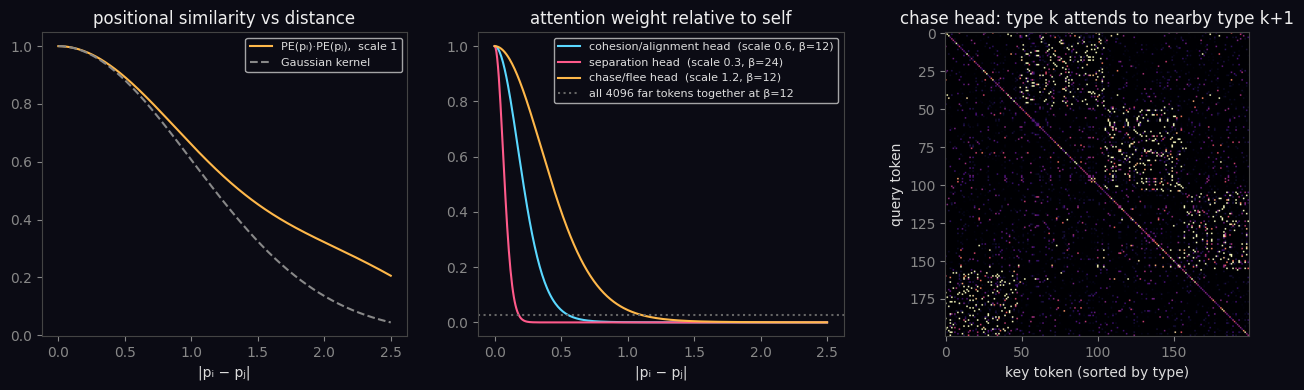

In [7]:
N_TOK, N_TYPES = 4096, 4          # attention cost grows as N_TOK²; 8192 is denser if the GPU is yours alone
BETA = 12.0                       # ≳ ln N_TOK, or the thousands of far tokens outweigh the few near ones
torch.manual_seed(1)
PE_DIRS = torch.randn(2, 32, device=device)                                  # 32 random 2-D frequencies

def pos_encode(P, scale):
    """(N, 2) → (N, 64): random Fourier features at length scale `scale`. With Gaussian
    frequencies, PE(pᵢ)·PE(pⱼ) ≈ exp(−|pᵢ−pⱼ|² / 2·scale²) — a clean bump in relative distance.
    Each head gets its own scale: that is its W_q / W_k."""
    ang = P @ (PE_DIRS / scale)
    return torch.cat([torch.sin(ang), torch.cos(ang)], 1) / math.sqrt(PE_DIRS.shape[1])

SCALE_LOCAL, SCALE_SEP, SCALE_CHASE = 0.6, 0.3, 1.2       # kernel widths of the three heads
BETA_SEP = 24.0                   # separation must not leak at all: a token with no neighbour must feel nothing

def attention(q, k, v, beta=1.0, causal_y=None, block=1024):
    """softmax(β q kᵀ) v — the whole mechanism. Queries are processed in blocks so the full
    N×N matrix never exists at once (the memory trick behind FlashAttention). With `causal_y`
    a token may only attend to tokens whose y is not above its own — a decoder mask."""
    out = torch.empty(q.shape[0], v.shape[1], device=q.device)
    for i in range(0, q.shape[0], block):
        s = beta * (q[i:i + block] @ k.T)
        if causal_y is not None:
            s = s.masked_fill(causal_y[None, :] > causal_y[i:i + block, None], -1e9)
        out[i:i + block] = torch.softmax(s, dim=1) @ v
    return out

# --- how far does each head see?  attention weight relative to self, versus distance ---
d   = torch.linspace(0, 2.5, 400, device=device)
P0  = torch.zeros(400, 2, device=device); P1 = torch.stack([torch.zeros_like(d), d], 1)
sim = (pos_encode(P0, 1.0) * pos_encode(P1, 1.0)).sum(1)
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].plot(d.cpu(), sim.cpu(), color='#ffb84a', label='PE(pᵢ)·PE(pⱼ),  scale 1')
axes[0].plot(d.cpu(), torch.exp(-d ** 2 / 2).cpu(), color='#888', ls='--', label='Gaussian kernel')
axes[0].set_title('positional similarity vs distance'); axes[0].set_xlabel('|pᵢ − pⱼ|'); axes[0].legend(fontsize=8)
for sc, beta, col, lab in [(SCALE_LOCAL, BETA, '#5ad8ff', 'cohesion/alignment'), (SCALE_SEP, BETA_SEP, '#ff5a8a', 'separation'),
                           (SCALE_CHASE, BETA, '#ffb84a', 'chase/flee')]:
    w = torch.exp(beta * ((pos_encode(P0, sc) * pos_encode(P1, sc)).sum(1) - 1))
    axes[1].plot(d.cpu(), w.cpu(), color=col, label=f'{lab} head  (scale {sc}, β={beta:.0f})')
axes[1].axhline(N_TOK * math.exp(-BETA), color='#666', ls=':', label=f'all {N_TOK} far tokens together at β={BETA:.0f}')
axes[1].set_title('attention weight relative to self'); axes[1].set_xlabel('|pᵢ − pⱼ|'); axes[1].legend(fontsize=8)

# --- an attention matrix: 200 random tokens, sorted by type, for the "chase" head ---
rngP   = torch.Generator(device=device).manual_seed(0)
Ps     = (torch.rand(200, 2, device=device, generator=rngP) * 2 - 1) * torch.tensor([DOM_W, DOM_H], device=device)
types  = torch.sort(torch.randint(0, N_TYPES, (200,), device=device, generator=rngP)).values
onehot = F.one_hot(types, N_TYPES).float()
pe      = pos_encode(Ps, SCALE_CHASE)
q_chase = torch.cat([pe, 0.5 * onehot], 1)                  # q·k = PE·PE + 0.25·[type_j = type_i + 1]
k_chase = torch.cat([pe, 0.5 * onehot.roll(-1, 1)], 1)      # near me, and of the *next* type
axes[2].imshow(attention(q_chase, k_chase, torch.eye(200, device=device), BETA).cpu(), cmap='magma', vmax=0.08)
axes[2].set_title('chase head: type k attends to nearby type k+1'); axes[2].set_xlabel('key token (sorted by type)'); axes[2].set_ylabel('query token')
plt.tight_layout(); plt.show()

### The screensaver: one attention layer per frame

Four thousand tokens, four types. A token's feature vector is its positional
encoding plus a one-hot type, so query–key similarity rewards *nearby* and
*same type*. Three heads ask different questions by encoding position at
different length scales — that is their $W_q$ and $W_k$:

| head | kernel width | β | values | output − own state | effect |
| --- | --- | --- | --- | --- | --- |
| cohesion / alignment | 0.6 | 12 | position, velocity | pull toward the local centroid, turn toward the local heading | flocking |
| separation | 0.3 | 24 | position | push *away* from the very-local centroid | personal space |
| chase / flee | 1.2 (+ type bonus) | 12 | position × one-hot type | pull toward nearby tokens of the next type, push away from the previous | perpetual pursuit |

The third head shows that values can carry structure: multiplying each token's
position by its one-hot type lets one softmax return a separate centroid (and
mass) for every type, and the query token then reads the two it cares about.

$\beta$ is not a free choice. A softmax over 4096 keys gives each far token a
weight of about $e^{-\beta}$ relative to a perfect match, so unless
$e^{\beta} \gg N$ the crowd of far tokens outweighs the handful of near ones and
every head degenerates into a pull toward the global centroid (the dotted
line in the plot above). This is the clustering behaviour the
transformer-as-particle-system papers prove. The separation head is the
touchiest: its output is multiplied by a large gain, so even a $10^{-2}$ leak
toward the centre becomes a steady push *away* from it and the swarm ends up
plastered against the walls — hence its sharper $\beta$.

Each frame is one layer: compute attention, add the result to the token's
velocity (residual), renormalise the speed (layer norm), move. Because the
chase is cyclic — gold hunts coral hunts teal hunts violet hunts gold, and
each flees its hunter — the swarm never settles; it rolls into spirals. Over the loop the cohesion temperature breathes and the
chase strength ebbs and flows, so flocks condense, scatter and re-form on a
slow 15-minute rhythm. Soft walls keep the swarm on the canvas. Set `causal=True` and a
token may only attend to tokens *below* it — the causal mask of a decoder,
drawn as "you may only look at your past".

In [8]:
class TransformerSaver:
    HUES = torch.tensor([[1.00, 0.78, 0.30], [1.00, 0.42, 0.38], [0.35, 0.95, 0.85], [0.70, 0.55, 1.00]], device=device)

    def __init__(self, n=N_TOK, seed=3, speed=0.6, causal=False):
        # (β breathes ±3 around BETA over the loop; the chase gain ebbs and flows)
        torch.manual_seed(seed)
        self.n, self.speed, self.causal = n, speed, causal
        self.P = (torch.rand(n, 2, device=device) * 2 - 1) * torch.tensor([DOM_W, DOM_H], device=device)
        self.V = F.normalize(torch.randn(n, 2, device=device), dim=1) * speed
        self.type = torch.randint(0, N_TYPES, (n,), device=device)
        self.onehot = F.one_hot(self.type, N_TYPES).float()
        self.canvas = Canvas(fade=0.955)

    @torch.no_grad()
    def step(self, t):
        beta_local = BETA + 3.0 * math.sin(phase(t, 3))                      # temperature breathes
        chase      = 0.5 + 0.5 * math.sin(phase(t, 2) + 1.0)                 # pursuit ebbs and flows
        cy   = self.P[:, 1] if self.causal else None
        vals = torch.cat([self.P, self.V], 1)                                # values = position & heading

        qk = torch.cat([pos_encode(self.P, SCALE_LOCAL), 0.5 * self.onehot], 1)   # q·k = PE·PE + 0.25·[same type]
        out_loc = attention(qk, qk, vals, beta_local, cy)                    # local centroid, local heading
        qk = pos_encode(self.P, SCALE_SEP)
        out_sep = attention(qk, qk, self.P, BETA_SEP, cy)                    # very-local centroid
        pe   = pos_encode(self.P, SCALE_CHASE)                               # chase/flee head: nearby tokens of the
        q_ch = torch.cat([pe, 0.5 * self.onehot], 1)                         #   next *or* previous type …
        k_ch = torch.cat([pe, 0.5 * (self.onehot.roll(-1, 1) + self.onehot.roll(1, 1))], 1)
        v_ch = torch.cat([(self.onehot[:, :, None] * self.P[:, None, :]).reshape(self.n, -1), self.onehot], 1)
        out  = attention(q_ch, k_ch, v_ch, BETA, cy)                         # … values carry per-type mass & centroid
        ar   = torch.arange(self.n, device=device)
        nxt, prv = (self.type + 1) % N_TYPES, (self.type - 1) % N_TYPES
        sums, mass = out[:, :8].reshape(self.n, N_TYPES, 2), out[:, 8:]
        to_next = sums[ar, nxt] - mass[ar, nxt, None] * self.P               # mass-weighted (centroid − me)
        to_prev = sums[ar, prv] - mass[ar, prv, None] * self.P

        dom  = torch.tensor([DOM_W, DOM_H], device=device)
        wall = -20.0 * torch.sign(self.P) * torch.clamp(self.P.abs() - (dom - 0.3), min=0)   # soft walls
        force = (3.0 * (out_loc[:, :2] - self.P) + 0.8 * (out_loc[:, 2:] - self.V)
                 - 40.0 * (out_sep - self.P)                                 # small vector, big gain
                 + 3.0 * chase * to_next - 2.0 * to_prev + wall)
        self.V = self.V + (force + 0.4 * torch.randn_like(self.V)) / FPS      # residual update (+ a little noise) …
        self.V = F.normalize(self.V, dim=1) * self.speed                      # … then "layer norm"
        self.P = torch.minimum(torch.maximum(self.P + self.V / FPS, -dom), dom)
        self.canvas.decay()
        self.canvas.splat(self.P, self.HUES[self.type], 0.12)
        return self.canvas.frame(gamma=0.75)

saver = TransformerSaver()
still = render_loop(saver.step, 'transformer_loop.mp4', still_at=LOOP_SECONDS * 0.4)
plt.imsave('transformer_still.png', still)
show_video('transformer_loop.mp4')

     60 s of video |   112 s elapsed | ~1428 s left


    120 s of video |   149 s elapsed | ~ 925 s left


    180 s of video |   183 s elapsed | ~ 711 s left


    240 s of video |   216 s elapsed | ~ 583 s left


    300 s of video |   249 s elapsed | ~ 491 s left


...

    660 s of video |   440 s elapsed | ~ 161 s left


    720 s of video |   472 s elapsed | ~ 120 s left


    780 s of video |   504 s elapsed | ~  80 s left


    840 s of video |   535 s elapsed | ~  40 s left


Saved → transformer_loop.mp4  (292 MB, 15.0 min of video, 584 s to render)


## Knobs to turn

| Knob | Where | Default | Effect |
| --- | --- | --- | --- |
| `LOOP_SECONDS` | environment variable | `900` | Loop length. Every driver is periodic in it, so any value loops cleanly. |
| `CANVAS_W/H`, `OUT_W/H` | setup cell | `240×720`, `480×1440` | Buffer and video resolution. Keep 1:3. |
| `fade` | each saver's `Canvas(...)` | `0.93–0.955` | Trail length. Closer to 1 = longer, smokier trails. |
| `SIG_MAX`, `SIG_HOLD`, `DENOISE`, `HOLD` | diffusion | `2.5`, `0.05`, `0.55`, `0.15` | How noisy "noise" is, how clean "clean" is, and how the cycle is split. |
| `make_target` | diffusion | five shapes | Add your own 2-D distribution; retrain for ~10 s. |
| `alpha`, `omega` | SSM | S4D-style line | Memory length and ring frequency of each oscillator. |
| `selective` | `SSMSaver(...)` | `True` | Turn off for a time-invariant SSM — the ringing is then identical above every bump. |
| `kappa`, `swirl`, `drift` | `SSMSaver` | wavelengths 3/1.5/1, `2.2`, `0.25` | Width of the vortex cells, strength of the swirl, upward flow. |
| `BETA`, `BETA_SEP` | transformer | `12`, `24` | Sharpness of the heads. Drop `BETA` toward `ln N_TOK ≈ 8.3` and the swarm collapses into one ball. |
| `SCALE_LOCAL/SEP/CHASE` | transformer | `0.6, 0.2, 1.2` | Positional kernel width of each head (see the receptive-field plot). |
| `force` gains | `TransformerSaver.step` | `3.0, 0.8, 40, 3.0, 2.0` | Cohesion, alignment, separation, chase, flee. More alignment = polarised flocks that press into the walls. |
| `causal` | `TransformerSaver(...)` | `False` | Decoder-style mask: attend only to tokens below you. |
| `N_TOK`, `n` | transformer / others | `4096`, `60k` | Token / particle count. Attention *time* grows as `N_TOK²` (memory doesn't — it's blocked). |

Output files: `diffusion_loop.mp4`, `ssm_loop.mp4`, `transformer_loop.mp4`
(15 minutes each, a few hundred MB — git-ignored) and a `*_still.png` poster
for each.